# nb01_data_check : HMS 데이터 구조 확인 및 EDA (M0)

- **가속기 : None (CPU)** : GPU 할당을 쓰지 않습니다.
- **입력** : 대회 데이터 `hms-harmful-brain-activity-classification` (Add Input으로 연결)
- **출력** : `/kaggle/working/figures/*.png`, `/kaggle/working/data_check_summary.json`

| 섹션 | 확인 내용 | 연결되는 결정 |
|---|---|---|
| 1 | 파일 목록, CSV 구조 | 「데이터셋 이해」 문서의 컬럼 정보 검증 |
| 2 | 고유 건수 (eeg_id, patient_id 등) | fold 분할 단위, 저장 용량 |
| 3 | 투표수·고득표 비율 | 고득표 기준(10표) 확정 |
| 4 | 클래스 분포 (전체/고득표/eeg_id 단위) | 불균형 대응 |
| 5 | eeg_id 내 중복 구간 | dedup 규칙 |
| 6 | 축 마스크·Seizure 이진 정답 비율 | 코드북 4-2 정의 검증 |
| 7 | EEG·스펙트로그램 parquet 헤더, 길이, 결측 | 전처리 규칙 |
| 8 | 처리 데이터 저장 용량 추정 | 20GB 출력 제한 대응 |
| 9 | EDA 그래프 4종 | 포트폴리오 그림 |

In [1]:
import os, json, glob, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Kaggle 입력 경로 자동 탐색 : 마운트 위치가 계정·노트북 버전에 따라 다를 수 있어 train.csv + train_eegs/ 위치로 찾는다
# (로컬 테스트 시 환경변수 HMS_DATA_DIR로 지정 가능)
def find_data_dir(root="/kaggle/input"):
    if os.environ.get("HMS_DATA_DIR"):
        return Path(os.environ["HMS_DATA_DIR"])
    for pattern in ["*/train.csv", "*/*/train.csv", "*/*/*/train.csv"]:
        for csv in sorted(Path(root).glob(pattern)):
            if (csv.parent / "train_eegs").is_dir():
                return csv.parent
    print("[경고] 대회 데이터를 찾지 못했습니다. 오른쪽 패널 Add Input에서 대회 데이터를 연결했는지 확인하세요.")
    print("/kaggle/input 내용:", [str(p) for p in Path(root).glob("*/*")][:20])
    return Path(root) / "hms-harmful-brain-activity-classification"

DATA_DIR = find_data_dir()
OUT_DIR = Path(os.environ.get("HMS_OUT_DIR", "/kaggle/working"))
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
HIGH_VOTE = 10          # 고득표 기준 (코드북 4-2)
N_FILE_SAMPLE = 300     # parquet 점검 표본 수 (CPU 시간 절약)
FS = 200                # EEG 샘플링 주파수

CLASSES = ["seizure", "lpd", "gpd", "lrda", "grda", "other"]
VOTE_COLS = [f"{c}_vote" for c in CLASSES]
rng = np.random.default_rng(SEED)
summary = {}
print("DATA_DIR :", DATA_DIR)
print("DATA_DIR exists:", DATA_DIR.exists())

DATA_DIR : /kaggle/input/competitions/hms-harmful-brain-activity-classification
DATA_DIR exists: True


## 1. 파일 목록 및 CSV 구조

In [2]:
for p in sorted(DATA_DIR.iterdir()):
    if p.is_dir():
        n = sum(1 for _ in p.glob("*.parquet"))
        print(f"[DIR ] {p.name:<28} parquet {n:,}개")
    else:
        print(f"[FILE] {p.name:<28} {p.stat().st_size/1e6:,.1f} MB")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sub = pd.read_csv(DATA_DIR / "sample_submission.csv")
print("\ntrain", train.shape, "| test", test.shape, "| sample_submission", sub.shape)
print("\ntrain 컬럼:", list(train.columns))
print("test 컬럼:", list(test.columns))
print("submission 컬럼:", list(sub.columns))
display(train.head())
display(train.dtypes.to_frame("dtype").T)
print("결측 수:", train.isna().sum()[train.isna().sum() > 0].to_dict() or "없음")
summary["train_shape"] = list(train.shape)
summary["test_shape"] = list(test.shape)

[DIR ] example_figures              parquet 0개
[FILE] sample_submission.csv        0.0 MB
[FILE] test.csv                     0.0 MB
[DIR ] test_eegs                    parquet 1개
[DIR ] test_spectrograms            parquet 1개
[FILE] train.csv                    7.6 MB
[DIR ] train_eegs                   parquet 17,300개
[DIR ] train_spectrograms           parquet 11,138개

train (106800, 15) | test (1, 3) | sample_submission (1, 7)

train 컬럼: ['eeg_id', 'eeg_sub_id', 'eeg_label_offset_seconds', 'spectrogram_id', 'spectrogram_sub_id', 'spectrogram_label_offset_seconds', 'label_id', 'patient_id', 'expert_consensus', 'seizure_vote', 'lpd_vote', 'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote']
test 컬럼: ['spectrogram_id', 'eeg_id', 'patient_id']
submission 컬럼: ['eeg_id', 'seizure_vote', 'lpd_vote', 'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote']


,eeg_id,eeg_sub_id,eeg_label_offset_seconds,spectrogram_id,spectrogram_sub_id,spectrogram_label_offset_seconds,label_id,patient_id,expert_consensus,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote
0,1628180742,0,0.0,353733,0,0.0,127492639,42516,Seizure,3,0,0,0,0,0
1,1628180742,1,6.0,353733,1,6.0,3887563113,42516,Seizure,3,0,0,0,0,0
2,1628180742,2,8.0,353733,2,8.0,1142670488,42516,Seizure,3,0,0,0,0,0
3,1628180742,3,18.0,353733,3,18.0,2718991173,42516,Seizure,3,0,0,0,0,0
4,1628180742,4,24.0,353733,4,24.0,3080632009,42516,Seizure,3,0,0,0,0,0


,eeg_id,eeg_sub_id,eeg_label_offset_seconds,spectrogram_id,spectrogram_sub_id,spectrogram_label_offset_seconds,label_id,patient_id,expert_consensus,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote
dtype,int64,int64,float64,int64,int64,float64,int64,int64,object,int64,int64,int64,int64,int64,int64


결측 수: 없음


## 2. 고유 건수

In [3]:
uniq = {c: int(train[c].nunique()) for c in ["eeg_id", "spectrogram_id", "patient_id", "label_id"]}
print(uniq)
rows_per_eeg = train.groupby("eeg_id").size()
eeg_per_patient = train.groupby("patient_id")["eeg_id"].nunique()
rows_per_patient = train.groupby("patient_id").size()
print("eeg_id당 구간 수 :", rows_per_eeg.describe().round(1).to_dict())
print("환자당 eeg_id 수 :", eeg_per_patient.describe().round(1).to_dict())
print("환자당 구간 수 상위 5 :", rows_per_patient.sort_values(ascending=False).head().to_dict())

# 한 eeg_id가 여러 spectrogram_id/patient_id에 걸치는지 (분할 단위 검증)
print("eeg_id당 patient_id 수 최대 :", train.groupby("eeg_id")["patient_id"].nunique().max())
print("eeg_id당 spectrogram_id 수 최대 :", train.groupby("eeg_id")["spectrogram_id"].nunique().max())
summary["unique"] = uniq
summary["rows_per_eeg_median"] = float(rows_per_eeg.median())

{'eeg_id': 17089, 'spectrogram_id': 11138, 'patient_id': 1950, 'label_id': 106800}
eeg_id당 구간 수 : {'count': 17089.0, 'mean': 6.2, 'std': 17.2, 'min': 1.0, '25%': 1.0, '50%': 3.0, '75%': 6.0, 'max': 743.0}
환자당 eeg_id 수 : {'count': 1950.0, 'mean': 8.8, 'std': 20.3, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 5.0, 'max': 270.0}
환자당 구간 수 상위 5 : {30631: 2215, 2641: 2185, 35627: 1403, 28330: 1362, 54199: 1350}
eeg_id당 patient_id 수 최대 : 1
eeg_id당 spectrogram_id 수 최대 : 1


## 3. 투표수 분포 및 고득표 비율

In [4]:
train["n_votes"] = train[VOTE_COLS].sum(axis=1)
print(train["n_votes"].describe().round(2).to_dict())
for th in [3, 5, 8, 10, 12, 15]:
    m = train["n_votes"] >= th
    print(f"n_votes >= {th:>2} : 구간 {m.mean():6.1%} ({m.sum():,}행), eeg_id {train.loc[m,'eeg_id'].nunique():,}개")
hv = train["n_votes"] >= HIGH_VOTE
summary["high_vote_threshold"] = HIGH_VOTE
summary["high_vote_row_ratio"] = float(hv.mean())
summary["high_vote_eeg_ids"] = int(train.loc[hv, "eeg_id"].nunique())

# 투표 확률(타깃) 생성 및 합 검증
P = train[VOTE_COLS].div(train["n_votes"], axis=0).values
assert np.allclose(P.sum(1), 1), "확률 합이 1이 아닌 행 존재"
train[[f"p_{c}" for c in CLASSES]] = P
# 합의도 : 최다 득표 비율
train["agreement"] = P.max(1)
print("합의도(최다 득표 비율) 평균 : 전체 %.3f / 고득표 %.3f" % (train["agreement"].mean(), train.loc[hv, "agreement"].mean()))

{'count': 106800.0, 'mean': 7.26, 'std': 5.65, 'min': 1.0, '25%': 3.0, '50%': 3.0, '75%': 13.0, 'max': 28.0}
n_votes >=  3 : 구간  93.7% (100,124행), eeg_id 12,309개
n_votes >=  5 : 구간  42.0% (44,806행), eeg_id 6,978개
n_votes >=  8 : 구간  37.4% (39,946행), eeg_id 5,939개
n_votes >= 10 : 구간  37.4% (39,946행), eeg_id 5,939개
n_votes >= 12 : 구간  33.9% (36,198행), eeg_id 5,521개
n_votes >= 15 : 구간  19.1% (20,430행), eeg_id 3,060개
합의도(최다 득표 비율) 평균 : 전체 0.816 / 고득표 0.688


## 4. 클래스 분포 (전체 / 고득표 / eeg_id 단위)

In [5]:
def class_dist(df):
    return df["expert_consensus"].str.lower().value_counts(normalize=True).reindex(CLASSES).fillna(0)

eeg_level = train.groupby("eeg_id").agg(patient_id=("patient_id", "first"),
                                         **{c: (c, "sum") for c in VOTE_COLS})
eeg_level["n_votes"] = eeg_level[VOTE_COLS].sum(axis=1)
eeg_level["expert_consensus"] = eeg_level[VOTE_COLS].idxmax(axis=1).str.replace("_vote", "")

dist = pd.DataFrame({
    "전체 구간": class_dist(train),
    "고득표 구간": class_dist(train[hv]),
    "eeg_id 단위(투표 합산)": class_dist(eeg_level),
}).round(3)
display(dist)
summary["class_dist"] = dist.to_dict()

,전체 구간,고득표 구간,eeg_id 단위(투표 합산)
expert_consensus,,,
seizure,0.196,0.015,0.159
lpd,0.139,0.186,0.151
gpd,0.156,0.252,0.106
lrda,0.156,0.156,0.055
grda,0.177,0.135,0.107
other,0.176,0.256,0.422


## 5. eeg_id 내 중복 구간 (dedup 규칙 근거)

In [6]:
def overlap_stats(g):
    off = np.sort(g["eeg_label_offset_seconds"].values)
    if len(off) < 2:
        return pd.Series({"n": len(off), "min_gap": np.nan, "overlap_ratio": 0.0, "label_change": 0})
    gaps = np.diff(off)
    lab_change = int((g.sort_values("eeg_label_offset_seconds")["expert_consensus"] != 
                      g.sort_values("eeg_label_offset_seconds")["expert_consensus"].shift()).sum() - 1)
    return pd.Series({"n": len(off), "min_gap": gaps.min(), "overlap_ratio": float((gaps < 50).mean()), "label_change": lab_change})

ov = train.groupby("eeg_id")[["eeg_label_offset_seconds", "expert_consensus"]].apply(overlap_stats)
multi = ov[ov["n"] > 1]
print(f"구간이 2개 이상인 eeg_id : {len(multi):,} / {len(ov):,}")
print(f"연속 구간 간격 < 50초(겹침) 비율 평균 : {multi['overlap_ratio'].mean():.1%}")
print(f"eeg_id 내부에서 최다 득표 클래스가 바뀌는 eeg_id 비율 : {(multi['label_change'] > 0).mean():.1%}")

# 같은 eeg_id 안에서 투표 분포가 완전히 같은 구간 비율
dup_votes = train.duplicated(subset=["eeg_id"] + VOTE_COLS, keep="first").mean()
print(f"eeg_id 내 투표 분포가 앞 구간과 동일한 행 비율 : {dup_votes:.1%}")
summary["eeg_with_multi_segments"] = int(len(multi))
summary["mean_overlap_ratio"] = float(multi["overlap_ratio"].mean())
summary["eeg_label_change_ratio"] = float((multi["label_change"] > 0).mean())
summary["dup_vote_row_ratio"] = float(dup_votes)

구간이 2개 이상인 eeg_id : 10,765 / 17,089
연속 구간 간격 < 50초(겹침) 비율 평균 : 100.0%
eeg_id 내부에서 최다 득표 클래스가 바뀌는 eeg_id 비율 : 7.3%
eeg_id 내 투표 분포가 앞 구간과 동일한 행 비율 : 81.1%


## 6. 축 보조 정답 마스크 및 Seizure 이진 정답 (코드북 4-2 검증)

In [7]:
four = train[["lpd_vote", "gpd_vote", "lrda_vote", "grda_vote"]].sum(axis=1)
train["axis_mask"] = (four > 0).astype(int)
train["axis_lat"] = np.where(four > 0, (train["lpd_vote"] + train["lrda_vote"]) / four.replace(0, np.nan), np.nan)
train["axis_pd"] = np.where(four > 0, (train["lpd_vote"] + train["gpd_vote"]) / four.replace(0, np.nan), np.nan)
train["y_seizure_bin"] = (train["p_seizure"] >= 0.5).astype(int)

print(f"axis_mask = 0 (4개 패턴 득표 없음) 비율 : {(train['axis_mask'] == 0).mean():.1%}")
print(f"axis_mask = 1 중 axis_lat ≥ 0.5 비율 : {(train.loc[train.axis_mask == 1, 'axis_lat'] >= 0.5).mean():.1%}")
print(f"axis_mask = 1 중 axis_pd ≥ 0.5 비율 : {(train.loc[train.axis_mask == 1, 'axis_pd'] >= 0.5).mean():.1%}")
print(f"고득표 구간 Seizure 양성 비율 : {train.loc[hv, 'y_seizure_bin'].mean():.1%} (n={hv.sum():,})")
summary["axis_mask0_ratio"] = float((train["axis_mask"] == 0).mean())
summary["seizure_pos_ratio_high_vote"] = float(train.loc[hv, "y_seizure_bin"].mean())

axis_mask = 0 (4개 패턴 득표 없음) 비율 : 25.3%
axis_mask = 1 중 axis_lat ≥ 0.5 비율 : 48.3%
axis_mask = 1 중 axis_pd ≥ 0.5 비율 : 46.5%
고득표 구간 Seizure 양성 비율 : 1.0% (n=39,946)


## 7. parquet 헤더, 길이, 결측 확인 (표본)

In [8]:
eeg_dir, spec_dir = DATA_DIR / "train_eegs", DATA_DIR / "train_spectrograms"
sample_eeg = rng.choice(train["eeg_id"].unique(), size=min(N_FILE_SAMPLE, train["eeg_id"].nunique()), replace=False)

e0 = pd.read_parquet(eeg_dir / f"{sample_eeg[0]}.parquet")
print("EEG 컬럼 :", list(e0.columns))
print("EEG dtype :", e0.dtypes.unique())

t0 = time.time()
rows = []
max_off = train.groupby("eeg_id")["eeg_label_offset_seconds"].max()
for eid in sample_eeg:
    df = pd.read_parquet(eeg_dir / f"{eid}.parquet")
    rows.append({"eeg_id": eid, "len_sec": len(df) / FS,
                 "nan_ratio": float(df.isna().values.mean()),
                 "all_nan_cols": int(df.isna().all().sum()),
                 "fits": (max_off[eid] + 50) * FS <= len(df)})
eeg_chk = pd.DataFrame(rows)
print(f"\n표본 {len(eeg_chk)}개 읽기 {time.time()-t0:.1f}초")
print("기록 길이(초) :", eeg_chk["len_sec"].describe().round(1).to_dict())
print(f"결측 비율 평균 {eeg_chk['nan_ratio'].mean():.3%}, 결측 있는 파일 비율 {(eeg_chk['nan_ratio'] > 0).mean():.1%}")
print(f"전체가 NaN인 채널이 있는 파일 : {(eeg_chk['all_nan_cols'] > 0).sum()}개")
print(f"offset + 50초가 기록 길이 안에 있는 비율 : {eeg_chk['fits'].mean():.1%}")
summary["eeg_columns"] = list(e0.columns)
summary["eeg_nan_file_ratio_sample"] = float((eeg_chk["nan_ratio"] > 0).mean())
summary["eeg_offset_fit_ratio_sample"] = float(eeg_chk["fits"].mean())

EEG 컬럼 : ['Fp1', 'F3', 'C3', 'P3', 'F7', 'T3', 'T5', 'O1', 'Fz', 'Cz', 'Pz', 'Fp2', 'F4', 'C4', 'P4', 'F8', 'T4', 'T6', 'O2', 'EKG']
EEG dtype : [dtype('float32')]

표본 300개 읽기 8.7초
기록 길이(초) : {'count': 300.0, 'mean': 81.1, 'std': 55.5, 'min': 50.0, '25%': 50.0, '50%': 60.0, '75%': 90.0, 'max': 582.0}
결측 비율 평균 0.198%, 결측 있는 파일 비율 5.3%
전체가 NaN인 채널이 있는 파일 : 0개
offset + 50초가 기록 길이 안에 있는 비율 : 100.0%


In [9]:
sid = train.loc[train["eeg_id"] == sample_eeg[0], "spectrogram_id"].iloc[0]
s0 = pd.read_parquet(spec_dir / f"{sid}.parquet")
regions = sorted({c.split("_")[0] for c in s0.columns if c != "time"})
freqs = sorted({float(c.split("_")[1]) for c in s0.columns if c != "time"})
print("스펙트로그램 shape :", s0.shape)
print("부위 :", regions, "| 주파수 개수 :", len(freqs), f"| 범위 {freqs[0]}~{freqs[-1]} Hz")
print("time 간격 :", np.unique(np.diff(s0["time"].values))[:5])
print(f"결측 비율 : {s0.isna().values.mean():.2%}")
summary["spec_regions"] = regions
summary["spec_freq_range"] = [freqs[0], freqs[-1]]
summary["spec_n_freq"] = len(freqs)

스펙트로그램 shape : (1179, 401)
부위 : ['LL', 'LP', 'RL', 'RP'] | 주파수 개수 : 100 | 범위 0.59~19.92 Hz
time 간격 : [2]
결측 비율 : 0.00%


## 8. 처리 데이터 저장 용량 추정 (출력 20GB 제한 대응)

In [10]:
n_eeg = train["eeg_id"].nunique()
n_rows = len(train)
bytes_eeg50 = 16 * 50 * FS * 2                    # 16채널 × 50초 × 200Hz × float16
bytes_spec10 = 4 * 100 * 300 * 2                  # 4부위 × 100주파수 × 300칸 × float16
est = {
    "50초 신호 / 전체 구간(GB)": n_rows * bytes_eeg50 / 1e9,
    "50초 신호 / eeg_id 1개(GB)": n_eeg * bytes_eeg50 / 1e9,
    "10분 스펙트로그램 / eeg_id 1개(GB)": n_eeg * bytes_spec10 / 1e9,
}
for k, v in est.items():
    print(f"{k:<36} {v:6.2f}  {'초과 위험' if v > 15 else 'OK'}")
summary["storage_estimate_gb"] = {k: round(v, 2) for k, v in est.items()}

50초 신호 / 전체 구간(GB)                    34.18  초과 위험
50초 신호 / eeg_id 1개(GB)                 5.47  OK
10분 스펙트로그램 / eeg_id 1개(GB)             4.10  OK


## 9. EDA 그래프 4종

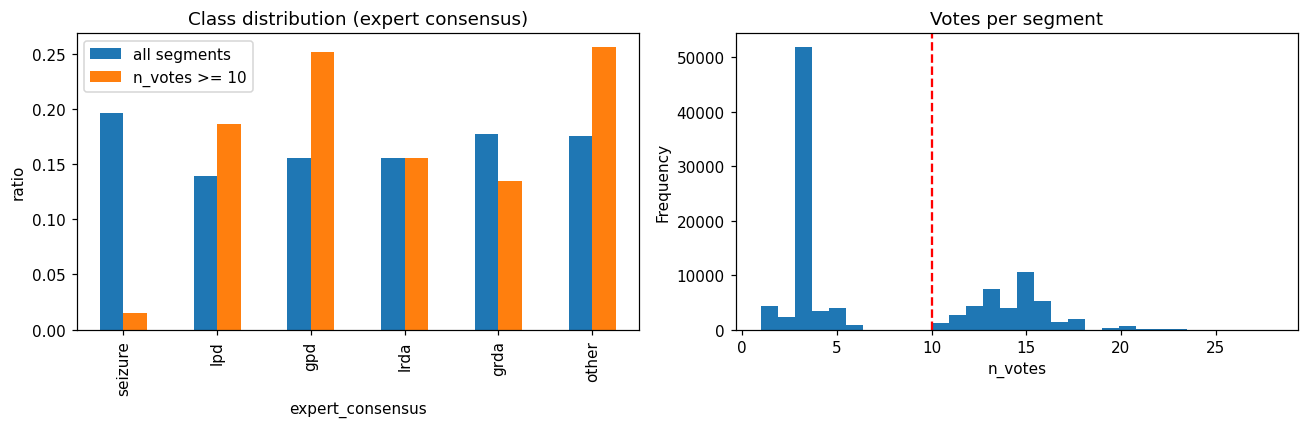

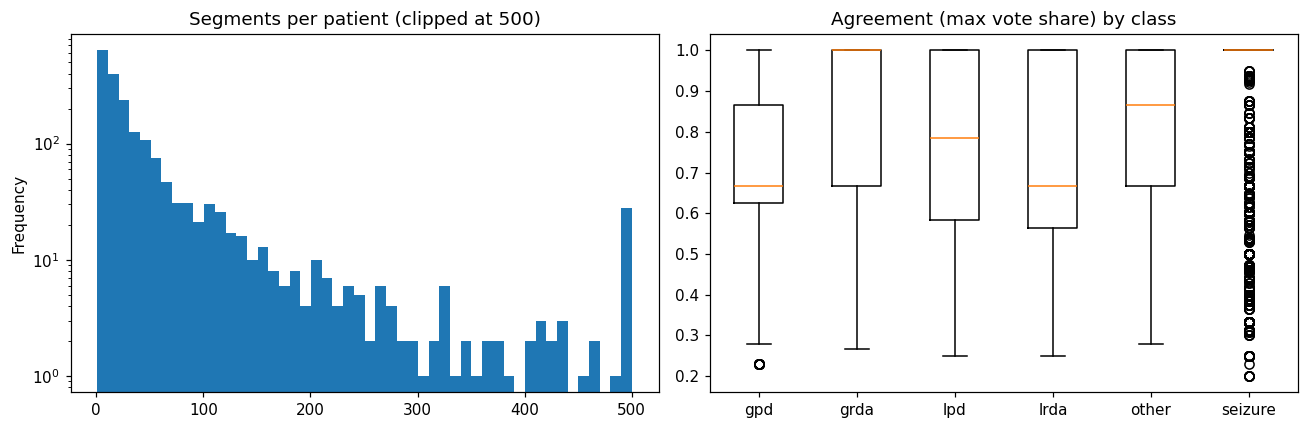

In [11]:
plt.rcParams["figure.dpi"] = 110
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
dist[["전체 구간", "고득표 구간"]].plot.bar(ax=ax[0])
ax[0].set_title("Class distribution (expert consensus)"); ax[0].set_ylabel("ratio")
ax[0].legend(["all segments", f"n_votes >= {HIGH_VOTE}"])
train["n_votes"].clip(upper=30).plot.hist(bins=30, ax=ax[1])
ax[1].axvline(HIGH_VOTE, color="r", ls="--"); ax[1].set_title("Votes per segment"); ax[1].set_xlabel("n_votes")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_class_and_votes.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rows_per_patient.clip(upper=500).plot.hist(bins=50, ax=ax[0], log=True)
ax[0].set_title("Segments per patient (clipped at 500)")
sns_data = train.groupby("expert_consensus")["agreement"].apply(list)
ax[1].boxplot(list(sns_data.values))
ax[1].set_xticks(range(1, len(sns_data) + 1)); ax[1].set_xticklabels([s.lower() for s in sns_data.index])
ax[1].set_title("Agreement (max vote share) by class")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_patient_and_agreement.png"); plt.show()

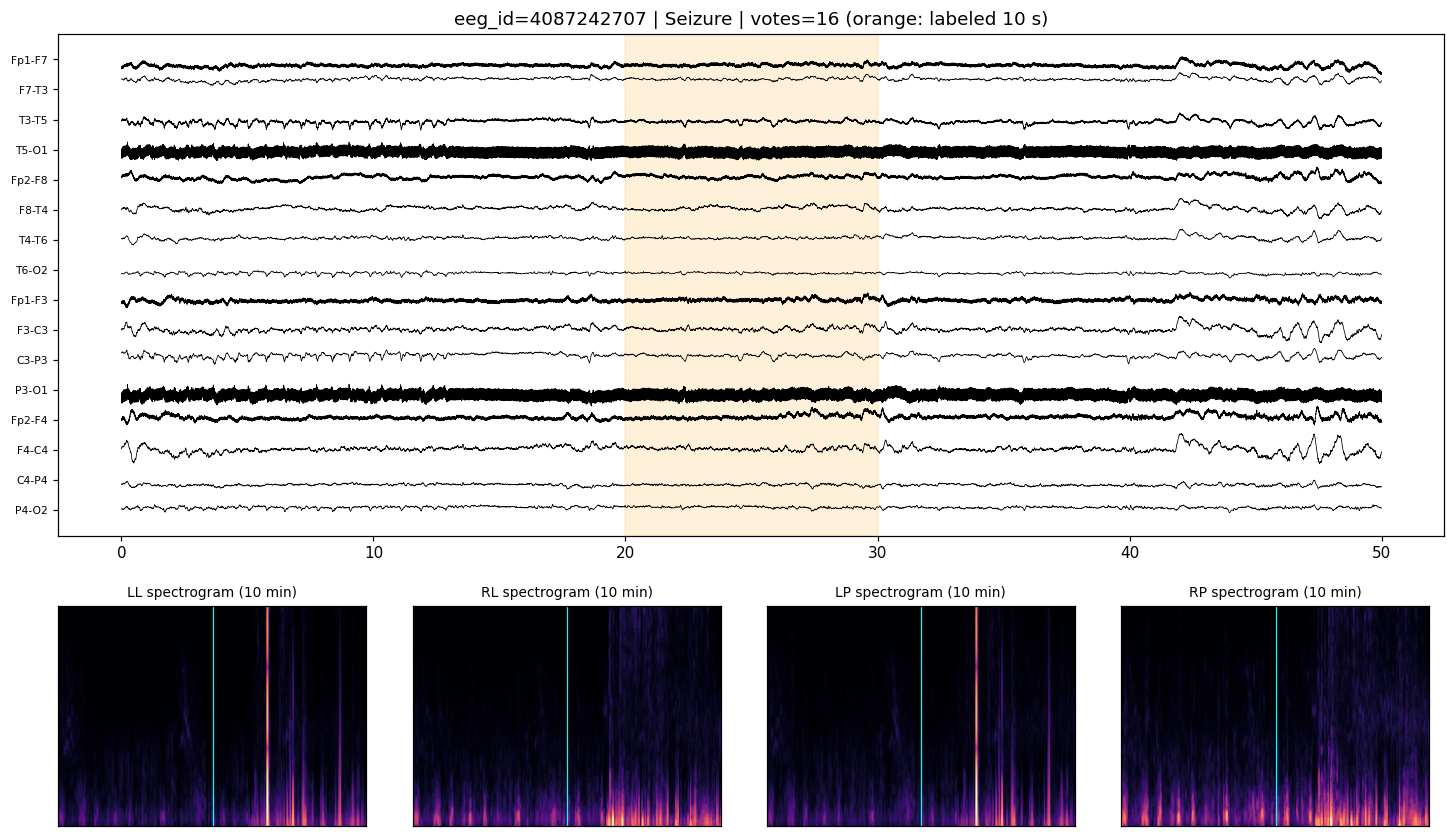

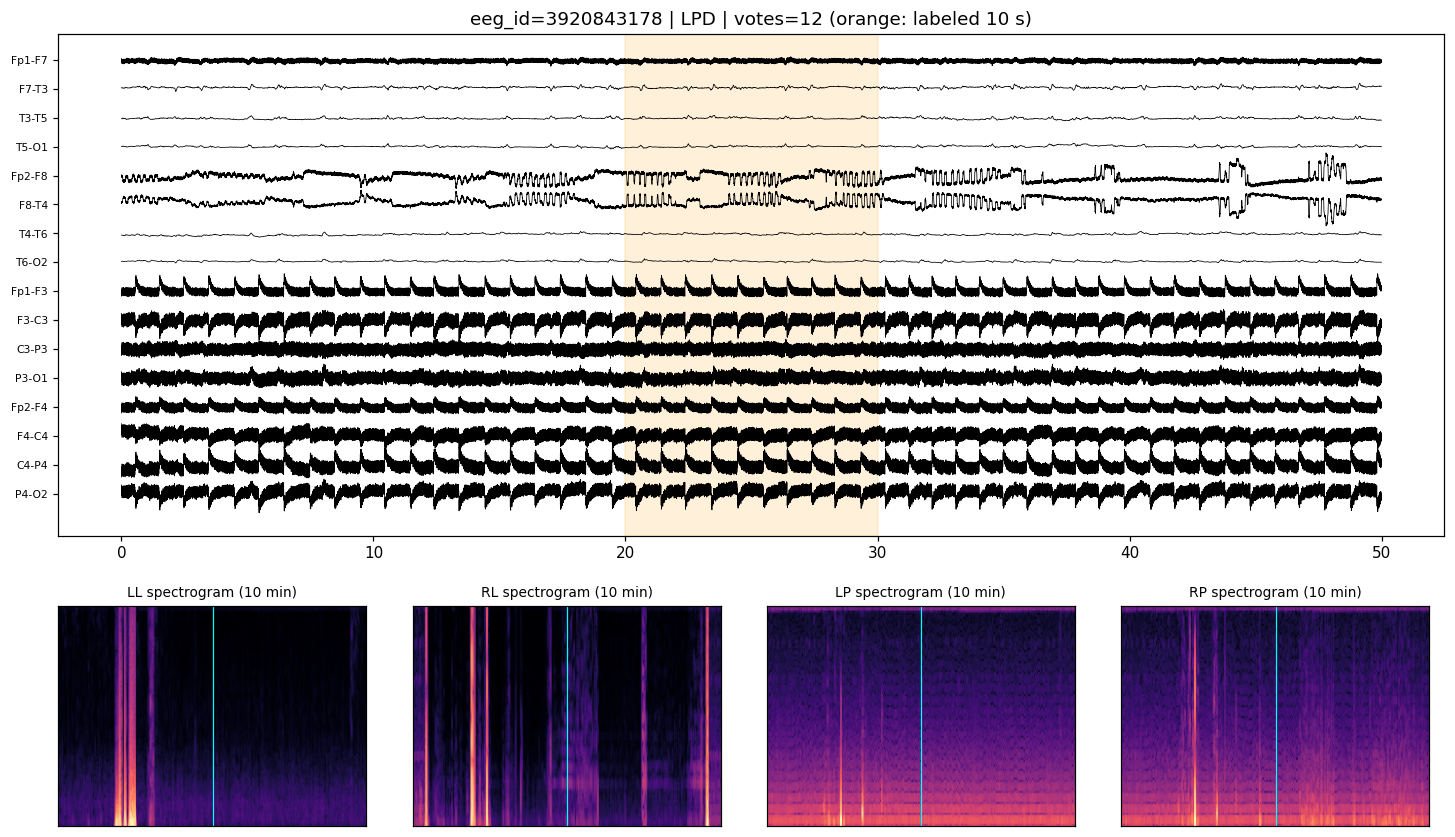

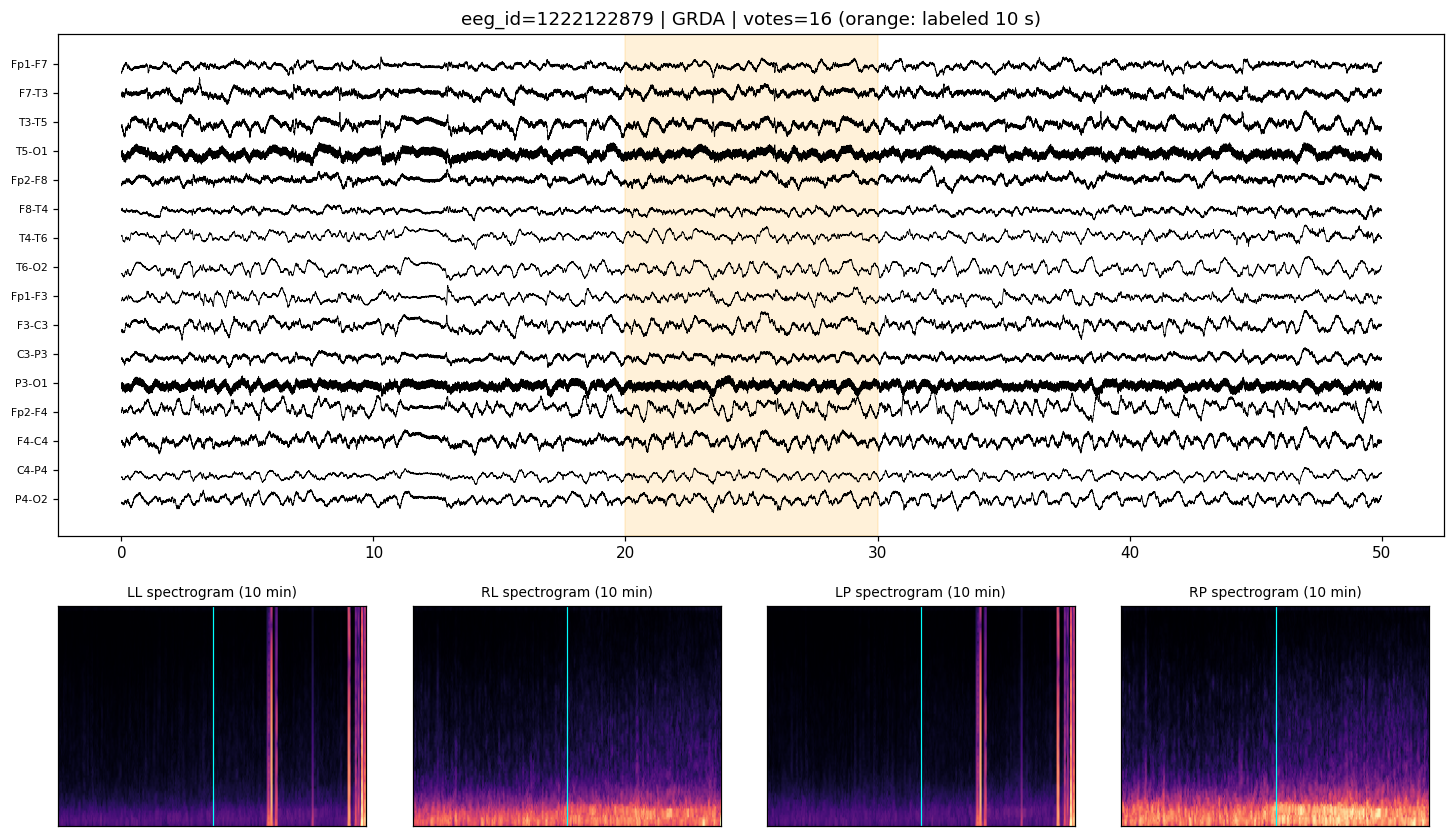

In [12]:
# 그림 3 : 동일 구간의 원본 EEG(더블 바나나) 와 10분 스펙트로그램 대응
CHAINS = {
    "LL": ["Fp1", "F7", "T3", "T5", "O1"],
    "RL": ["Fp2", "F8", "T4", "T6", "O2"],
    "LP": ["Fp1", "F3", "C3", "P3", "O1"],
    "RP": ["Fp2", "F4", "C4", "P4", "O2"],
}

def double_banana(eeg):
    out = {}
    for name, ch in CHAINS.items():
        for a, b in zip(ch[:-1], ch[1:]):
            out[f"{a}-{b}"] = eeg[a].values - eeg[b].values
    return pd.DataFrame(out)

def plot_pair(row, fname):
    eeg = pd.read_parquet(eeg_dir / f"{row.eeg_id}.parquet")
    s = int(row.eeg_label_offset_seconds * FS)
    seg = double_banana(eeg.iloc[s:s + 50 * FS]).interpolate(limit_direction="both").fillna(0)
    spec = pd.read_parquet(spec_dir / f"{row.spectrogram_id}.parquet")
    so = row.spectrogram_label_offset_seconds
    spec = spec[(spec["time"] >= so) & (spec["time"] < so + 600)]

    fig = plt.figure(figsize=(14, 8))
    ax1 = fig.add_axes([0.05, 0.38, 0.9, 0.57])
    t = np.arange(len(seg)) / FS
    scale = np.nanpercentile(np.abs(seg.values), 99) + 1e-6
    for i, c in enumerate(seg.columns):
        ax1.plot(t, seg[c].values / scale - i * 2.5, lw=0.5, color="k")
    ax1.set_yticks([-i * 2.5 for i in range(len(seg.columns))]); ax1.set_yticklabels(seg.columns, fontsize=7)
    ax1.axvspan(20, 30, color="orange", alpha=0.15)
    ax1.set_title(f"eeg_id={row.eeg_id} | {row.expert_consensus} | votes={int(row.n_votes)} (orange: labeled 10 s)")
    for k, r in enumerate(["LL", "RL", "LP", "RP"]):
        ax = fig.add_axes([0.05 + k * 0.23, 0.05, 0.2, 0.25])
        cols = [c for c in spec.columns if c.startswith(r + "_")]
        img = np.log1p(spec[cols].fillna(0).values.T)
        ax.imshow(img, aspect="auto", origin="lower", cmap="magma")
        ax.axvline(img.shape[1] / 2, color="cyan", lw=0.8)
        ax.set_title(f"{r} spectrogram (10 min)", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    plt.savefig(FIG_DIR / fname); plt.show()

hv_df = train[hv]
for c in ["Seizure", "LPD", "GRDA"]:
    cand = hv_df[hv_df["expert_consensus"] == c]
    if len(cand):
        plot_pair(cand.sample(1, random_state=SEED).iloc[0], f"03_eeg_vs_spec_{c.lower()}.png")

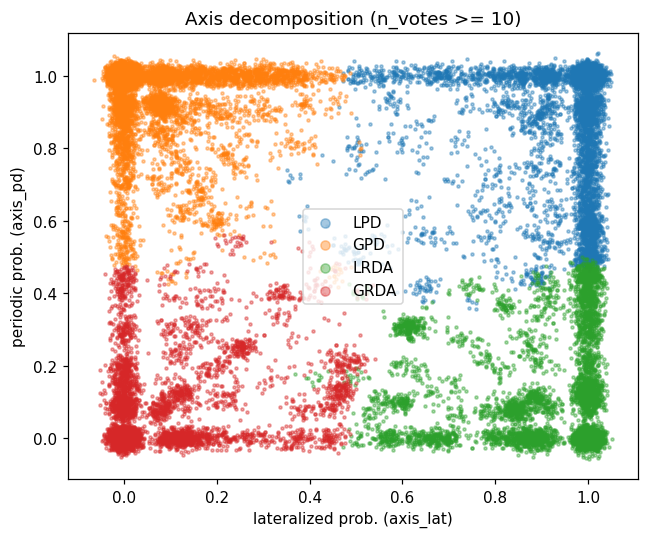

In [13]:
# 그림 4 : 축 분해 관점 분포 (편측 확률 vs 주기성 확률)
m = (train["axis_mask"] == 1) & hv
fig, ax = plt.subplots(figsize=(6, 5))
for c, col in zip(["LPD", "GPD", "LRDA", "GRDA"], ["C0", "C1", "C2", "C3"]):
    d = train[m & (train["expert_consensus"] == c)]
    jitter = rng.normal(0, 0.015, size=(len(d), 2))
    ax.scatter(d["axis_lat"] + jitter[:, 0], d["axis_pd"] + jitter[:, 1], s=4, alpha=0.4, label=c, color=col)
ax.set_xlabel("lateralized prob. (axis_lat)"); ax.set_ylabel("periodic prob. (axis_pd)")
ax.set_title(f"Axis decomposition (n_votes >= {HIGH_VOTE})"); ax.legend(markerscale=3)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_axis_decomposition.png"); plt.show()

## 10. 요약 저장

In [14]:
with open(OUT_DIR / "data_check_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=float)
print(json.dumps(summary, ensure_ascii=False, indent=2, default=float)[:3000])
print("\n저장 파일 :", sorted(p.name for p in FIG_DIR.glob("*.png")))

{
  "train_shape": [
    106800,
    15
  ],
  "test_shape": [
    1,
    3
  ],
  "unique": {
    "eeg_id": 17089,
    "spectrogram_id": 11138,
    "patient_id": 1950,
    "label_id": 106800
  },
  "rows_per_eeg_median": 3.0,
  "high_vote_threshold": 10,
  "high_vote_row_ratio": 0.3740262172284644,
  "high_vote_eeg_ids": 5939,
  "class_dist": {
    "전체 구간": {
      "seizure": 0.196,
      "lpd": 0.139,
      "gpd": 0.156,
      "lrda": 0.156,
      "grda": 0.177,
      "other": 0.176
    },
    "고득표 구간": {
      "seizure": 0.015,
      "lpd": 0.186,
      "gpd": 0.252,
      "lrda": 0.156,
      "grda": 0.135,
      "other": 0.256
    },
    "eeg_id 단위(투표 합산)": {
      "seizure": 0.159,
      "lpd": 0.151,
      "gpd": 0.106,
      "lrda": 0.055,
      "grda": 0.107,
      "other": 0.422
    }
  },
  "eeg_with_multi_segments": 10765,
  "mean_overlap_ratio": 1.0,
  "eeg_label_change_ratio": 0.07273571760334417,
  "dup_vote_row_ratio": 0.8110205992509363,
  "axis_mask0_ratio": 0.2526966

## 다음 단계 체크리스트 (결과 확인 후 「코드북_수정」에 기록)

- [ ] 고득표 기준 10표 유지 여부 (섹션 3의 비율 확인)
- [ ] dedup 방식 결정 : eeg_id 대표 구간 vs 투표 합산 (섹션 5)
- [ ] axis_mask = 0 비율 확인 후 보조 손실 가중치 결정 (섹션 6)
- [ ] 결측 처리 규칙 확정 : 전체 NaN 채널 처리 방식 (섹션 7)
- [ ] 저장 형식 결정 : 50초 신호 eeg_id 1개 저장 가능 여부 (섹션 8)
- [ ] 「데이터셋 이해」 문서의 컬럼 정보를 실제 값으로 갱신